# Beauty-meson decay analysis

Study $B_s^0\to K^+\pi^-K^-\pi^+$ using particle-identification cuts, alternative mass hypotheses, a boosted decision tree, an extended mass fit and signal-weighted invariant-mass projections.

`data.root` and `mc.root` are course-provided samples from Matt Kenzie's [CERN course directory](https://cern.ch/mkenzie/mphil/assignment/2526/). Set `A3_DATA_DIR` or place them in `data/`. The ROOT files are external inputs and are not distributed here.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from a3_sol_ex import analysis, plotting

get_ipython().run_line_magic("matplotlib", "inline")
plt.style.use("mphil.mplstyle")
Path("figures").mkdir(exist_ok=True)


## Input data

Each file contains a `DecayTree`. Only branches used below are loaded. Masses are in MeV/$c^2$, momenta in MeV/$c$, and flight distances in mm. The MC `weight` branch corrects simulation–data discrepancies and is used in distribution overlays; the classifier uses class-balancing weights.


The course [Info.md](https://cern.ch/mkenzie/mphil/assignment/2526/Info.md) describes the branches.


### Candidate masses


In [2]:
track_branches = [f"{track}_{axis}" for track in ("Kp", "pim", "Km", "pip") for axis in ("PX", "PY", "PZ")]
pid_branches = ["pip_ProbNNpi", "pim_ProbNNpi", "Kp_ProbNNp", "Km_ProbNNp", "Kp_ProbNNk", "Km_ProbNNk"]
feature_branches = ["Bs_CosMomentumDecayAngle", "Bs_DecayVertex_Chi2pDoF", "Bs_ImpactParameter_Chi2", "Bs_FlightDistance_Chi2", "Bs_FlightDistance", "Bs_PT"]
branches = ["Bs_M", "Kst_M", "Kstb_M"] + track_branches + pid_branches + feature_branches

df_data = analysis.load_dataframe("data", branches)
df_mc = analysis.load_dataframe("mc", branches)
print(f"Data: {len(df_data):,} candidates; simulation: {len(df_mc):,} candidates")


Data: 939,429 candidates; simulation: 5,357,612 candidates


Inspect the candidate mass and compare the data with weighted signal simulation.


In [3]:
# Bs mass
_ = plotting.plot_bs_mass_overlay(df_data, df_mc)


The $K\pi$ mass plane shows the two intermediate mass combinations.


In [4]:
# K* mass plane
_ = plotting.plot_kstar_mass_plane(df_data)


The separate $K\pi$ spectra provide a first view of the resonant structure.


In [5]:
# K* masses (1x2 layout)
_ = plotting.plot_kstar_mass_overlays(df_data, df_mc)


## Alternative mass hypotheses

Recompute four-track invariant masses after changing one track's assumed particle mass. Enhancements near known hadron masses motivate vetoes; a mass swap alone does not uniquely establish a decay channel.


In [6]:
MK, MPI, MP = analysis.MK, analysis.MPI, analysis.MP

swaps = [
    # (swap dict,  title)
    ({"pip": MK},  r"(a) $\pi^+\to K^+$"),
    ({"pim": MK},  r"(b) $\pi^-\to K^-$"),
    ({"Kp": MPI},  r"(c) $K^+\to\pi^+$"),
    ({"Km": MPI},  r"(d) $K^-\to\pi^-$"),
    ({"Kp": MP},   r"(e) $K^+\to p$"),
    ({"Km": MP},   r"(f) $K^-\to\bar{p}$"),
]

mass_arrays = [analysis.compute_mass_swap(df_data, s) for s, _ in swaps]
titles      = [t for _, t in swaps]

_ = plotting.plot_mass_hypothesis_grid(mass_arrays, titles)


### Mass vetoes

Reject candidates lying within 60 MeV/$c^2$ of the $B^0$ reference mass when a pion is assigned a kaon mass, or within 50 MeV/$c^2$ of the $\Lambda_b$ reference mass when a kaon is assigned a proton mass.


The same mass vetoes are applied to data and signal simulation.


In [7]:
VETO_HALF_WIDTH_BD = 60   # width around B0 mass (5279.7)
VETO_HALF_WIDTH_LB = 50   # width around Lb mass (5619.6)

df_data_vetoed = analysis.apply_peaking_background_veto(df_data, veto_half_width_bd=VETO_HALF_WIDTH_BD, veto_half_width_lb=VETO_HALF_WIDTH_LB)
print(f"Events before veto: {len(df_data):>8,}")
print(f"Events after  veto: {len(df_data_vetoed):>8,}")
print(f"Fraction removed: {1 - len(df_data_vetoed)/len(df_data):.2%}")

_ = plotting.plot_bs_mass_before_after(df_data, df_data_vetoed, labels=("Before veto", "After veto"))


Events before veto:  939,429
Events after  veto:  492,280
Fraction removed: 47.60%


### Particle identification

Compare a signal-enriched mass window with samples selected by alternative mass hypotheses. These samples are mixtures, so the distributions provide selection diagnostics rather than truth labels.


In [8]:
# Compute recomputed masses for enriched subsamples
m_pip_as_Kp = analysis.compute_mass_swap(df_data, {"pip": analysis.MK})  # pi+ -> K+ (B0 test)
m_Kp_as_p   = analysis.compute_mass_swap(df_data, {"Kp":  analysis.MP})  # K+ -> p  (Lb test)

# Define enriched subsamples from DATA
mask_sig = (df_data["Bs_M"] > 5340) & (df_data["Bs_M"] < 5400)
mask_bd  = (m_pip_as_Kp > 5250) & (m_pip_as_Kp < 5310)
mask_lb  = (m_Kp_as_p   > 5590) & (m_Kp_as_p   < 5650)

df_sig_enr = df_data[mask_sig]
df_bd_enr  = df_data[mask_bd]
df_lb_enr  = df_data[mask_lb]

print(f"Signal-enriched : {len(df_sig_enr):>6,} events")
print(f"B0-enriched     : {len(df_bd_enr):>6,} events")
print(f"Lb-enriched     : {len(df_lb_enr):>6,} events")

pid_vars = [
    {"col": "pip_ProbNNpi", "xlabel": r"$\pi^+$ ProbNN$\pi$"},
    {"col": "pim_ProbNNpi", "xlabel": r"$\pi^-$ ProbNN$\pi$"},
    {"col": "Kp_ProbNNp",   "xlabel": r"$K^+$ ProbNN$p$"},
    {"col": "Km_ProbNNp",   "xlabel": r"$K^-$ ProbNN$p$"},
    {"col": "Kp_ProbNNk",   "xlabel": r"$K^+$ ProbNN$k$"},
    {"col": "Km_ProbNNk",   "xlabel": r"$K^-$ ProbNN$k$"},
]
_ = plotting.plot_pid_enriched_grid(df_sig_enr, df_bd_enr, df_lb_enr, pid_vars)


Signal-enriched : 131,924 events
B0-enriched     : 74,709 events
Lb-enriched     : 94,880 events


The proton and kaon PID variables motivate the cuts `Kp_ProbNNp < 0.5`, `Kp_ProbNNk > 0.3` and `Km_ProbNNk > 0.3`.


In [9]:
# reject Lb and B0 background
pid_mask = (df_data["Kp_ProbNNp"] < 0.5)&(df_data["Kp_ProbNNk"] > 0.3)&(df_data["Km_ProbNNk"] > 0.3)

df_data_pid = df_data[pid_mask].reset_index(drop=True)

print(f"Events before PID cuts: {len(df_data):>8,}")
print(f"Events after  PID cuts: {len(df_data_pid):>8,}")
print(f"Fraction removed: {1 - len(df_data_pid)/len(df_data):.2%}")

_ = plotting.plot_bs_mass_before_after(df_data, df_data_pid, labels=("Before PID cuts", "After PID cuts"))


Events before PID cuts:  939,429
Events after  PID cuts:  387,681
Fraction removed: 58.73%


Combine the PID selection with the mass vetoes, applying identical cuts to data and MC.


In [10]:
df_data_precut = analysis.apply_peaking_background_veto(df_data_pid, veto_half_width_bd=VETO_HALF_WIDTH_BD, veto_half_width_lb=VETO_HALF_WIDTH_LB)

# Apply same to MC
mc_pid_mask = (
    (df_mc["Kp_ProbNNk"] > 0.3) &
    (df_mc["Km_ProbNNk"] > 0.3) &
    (df_mc["Kp_ProbNNp"] < 0.5)
)
df_mc_pid = df_mc[mc_pid_mask].reset_index(drop=True)
df_mc_precut = analysis.apply_peaking_background_veto(
    df_mc_pid,
    veto_half_width_bd=VETO_HALF_WIDTH_BD,
    veto_half_width_lb=VETO_HALF_WIDTH_LB,
)

print(f"Data after PID + vetoes: {len(df_data_precut):>8,}")
print(f"MC after PID + vetoes: {len(df_mc_precut):>8,}")
print(f"MC signal efficiency: {len(df_mc_precut)/len(df_mc):.2%}")

_ = plotting.plot_bs_mass_before_after(df_data, df_data_precut)


Data after PID + vetoes:  202,994
MC after PID + vetoes: 2,085,856
MC signal efficiency: 38.93%


## Combinatorial-background classifier

Signal simulation and data sidebands ($m<5250$ or $m>5550$ MeV/$c^2$) define the classification samples. Six features describe pointing angle, decay-vertex quality, impact-parameter significance, flight-distance significance, flight distance and transverse momentum. The first five use logarithmic transforms. The candidate mass is excluded.

Use 30% of the combined sample and a seeded 80/20 training/validation split. The scaler is fitted only on training rows. Class-balancing weights compensate for unequal signal and sideband counts; they are distinct from the MC correction weights.


In [11]:
df_bkg_train = df_data_precut[(df_data_precut["Bs_M"] < 5250) | (df_data_precut["Bs_M"] > 5550)]


### BDT configuration

Use histogram gradient boosting with depth 3, learning rate 0.1 and at most 400 boosting iterations. The held-out score is a validation diagnostic for the chosen configuration, not an independent final test estimate.


In [12]:
best_hp = {"max_depth": 3, "learning_rate": 0.1, "max_iter": 400}


Train one classifier and retain split-specific score distributions for the diagnostic below.


In [13]:
bdt_split = analysis.train_bdt_with_splits(df_mc_precut, df_bkg_train, **best_hp)
bdt, scaler = bdt_split["bdt"], bdt_split["scaler"]
print(f"Class-balanced validation accuracy: {bdt_split['accuracy']:.4f}")
print(f"Configuration: {best_hp}")


Class-balanced validation accuracy: 0.9263
Configuration: {'max_depth': 3, 'learning_rate': 0.1, 'max_iter': 400}


### Training and validation score distributions


In [14]:
# Overtraining check: train vs validation score distributions
_ = plotting.plot_bdt_train_validation(
    bdt_split["train_sig_scores"],
    bdt_split["train_bkg_scores"],
    bdt_split["validation_sig_scores"],
    bdt_split["validation_bkg_scores"],
)


### Scores across the selected samples


In [15]:
# Score all pre-cut data and MC
bdt_scores = analysis.score_bdt(df_data_precut, bdt, scaler)
bdt_scores_mc = analysis.score_bdt(df_mc_precut, bdt, scaler)

_ = plotting.plot_bdt_scores(bdt_scores, bdt_scores_mc, df_data_precut, sb_cut=5550)


### Threshold selection

Scan $S/\sqrt{S+B}$ using counts in 5340–5400 MeV/$c^2$ and sideband counts rescaled by window width. This is a working selection criterion with a locally flat-background approximation; it is not a discovery significance or an independent performance estimate.


In [16]:
# Optimise BDT cut: S / sqrt(S + B)
SIGNAL_WINDOW = (5340, 5400)

thresholds = np.linspace(0.1, 0.99, 100)
significances = []

for t in thresholds:
    mask_cut = bdt_scores >= t
    mass_cut = df_data_precut.loc[mask_cut, "Bs_M"].to_numpy(float)

    in_sig = (mass_cut > SIGNAL_WINDOW[0]) & (mass_cut < SIGNAL_WINDOW[1])
    sig_width = SIGNAL_WINDOW[1] - SIGNAL_WINDOW[0]
    sb_lo = (mass_cut > 5200) & (mass_cut < SIGNAL_WINDOW[0])
    sb_hi = (mass_cut > SIGNAL_WINDOW[1]) & (mass_cut < 5600)
    sb_width = (SIGNAL_WINDOW[0] - 5200) + (5600 - SIGNAL_WINDOW[1])

    n_sb = np.sum(sb_lo) + np.sum(sb_hi)
    B = n_sb * sig_width / sb_width if sb_width > 0 else 0
    S = np.sum(in_sig) - B

    if S + B > 0 and S > 0:
        significances.append(S / np.sqrt(S + B))
    else:
        significances.append(0)

significances = np.array(significances)
best_idx = np.argmax(significances)
best_cut = thresholds[best_idx]

_ = plotting.plot_bdt_optimisation(thresholds, significances, best_cut)

print(f"Optimal BDT cut     : {best_cut:.3f}")
print(f"Max S/sqrt(S+B)     : {significances[best_idx]:.2f}")


Optimal BDT cut     : 0.181
Max S/sqrt(S+B)     : 140.14


In [17]:
# Apply BDT cut
BDT_CUT = best_cut
mask_bdt = bdt_scores >= BDT_CUT
df_data_clean = df_data_precut[mask_bdt].reset_index(drop=True)

# Apply same to MC
mask_bdt_mc = analysis.score_bdt(df_mc_precut, bdt, scaler) >= BDT_CUT
df_mc_clean = df_mc_precut[mask_bdt_mc].reset_index(drop=True)

print(f"BDT threshold              : {BDT_CUT:.3f}")
print(f"Data before BDT cut        : {len(df_data_precut):>8,}")
print(f"Data after  BDT cut        : {len(df_data_clean):>8,}")
print(f"Fraction removed           : {1 - len(df_data_clean)/len(df_data_precut):.2%}")
print(f"MC signal efficiency       : {len(df_mc_clean)/len(df_mc):.2%}")

_ = plotting.plot_bs_mass_before_after(df_data_precut, df_data_clean, labels=("Before BDT cut", "After BDT cut"))


BDT threshold              : 0.181
Data before BDT cut        :  202,994
Data after  BDT cut        :   58,232
Fraction removed           : 71.31%
MC signal efficiency       : 38.43%


### Selected candidate mass


In [18]:
# Final mass comparison across selection stages
_ = plotting.plot_selection_stages([
    (df_data,        "Raw data",           "tab:gray"),
    (df_data_precut, "After PID + vetoes", "tab:orange"),
    (df_data_clean,  "After all cuts",     "tab:blue"),
])


## Extended mass fit

Fit 100 bins over 5200–5550 MeV/$c^2$ with a Crystal Ball plus Gaussian signal shape sharing one mean, an exponential combinatorial component, and a Gaussian residual $B^0$ component. All PDFs are normalised within the fit window. The three yields and nine shape parameters float with bounded ranges.


The fit returns Minuit diagnostics, parameter estimates and Hesse errors. The displayed pulls use integrated expectations in the same bins as the fit.


In [19]:
# Perform mass fit
mass = df_data_clean["Bs_M"].to_numpy(float)
FIT_RANGE = (5200, 5550)

fit_result = analysis.fit_bs_mass(mass, mass_range=FIT_RANGE)


In [20]:
fit = fit_result["minuit"]
print(f"Valid minimum: {fit.valid}; accurate covariance: {fit.fmin.has_accurate_covar}")
print(f"Parameters at a limit: {fit.fmin.has_parameters_at_limit}")
print(f"Binned deviance / degrees of freedom: {fit.fval:.2f} / {fit.ndof}")


Valid minimum: True; accurate covariance: True
Parameters at a limit: True
Binned deviance / degrees of freedom: 135.98 / 88.0


In [21]:
p = fit_result["params"]
e = fit_result["errors"]

print(f"Fit valid          : {fit_result['valid']}")
print(f"Events in fit range: {fit_result['n_events']:,}")
print(f"\nSignal parameters:")
print(f"  mu       = {p['mu']:.2f} +/- {e['mu']:.2f} MeV/c\u00b2")
print(f"  sg1 (CB) = {p['sg1']:.2f} +/- {e['sg1']:.2f} MeV/c\u00b2")
print(f"  sg2 (G)  = {p['sg2']:.2f} +/- {e['sg2']:.2f} MeV/c\u00b2")
print(f"  f_CB     = {p['fcb']:.3f} +/- {e['fcb']:.3f}")
print(f"  beta     = {p['beta']:.2f} +/- {e['beta']:.2f}")
print(f"  m_CB     = {p['m_cb']:.2f} +/- {e['m_cb']:.2f}")
print(f"\nYields:")
print(f"  N_sig    = {p['nsig']:.0f} +/- {e['nsig']:.0f}")
print(f"  N_bkg    = {p['nbkg']:.0f} +/- {e['nbkg']:.0f}")
print(f"  N_Bd     = {p['nbd']:.0f} +/- {e['nbd']:.0f}")
print(f"\nBackground parameters:")
print(f"  lambda   = {p['lam']:.5f} +/- {e['lam']:.5f}")
print(f"  mu_d     = {p['mu_d']:.2f} +/- {e['mu_d']:.2f} MeV/c\u00b2")
print(f"  sg_d     = {p['sg_d']:.2f} +/- {e['sg_d']:.2f} MeV/c\u00b2")


Fit valid          : True
Events in fit range: 42,124

Signal parameters:
  mu       = 5364.76 +/- 0.22 MeV/c²
  sg1 (CB) = 15.61 +/- 0.32 MeV/c²
  sg2 (G)  = 36.55 +/- 2.45 MeV/c²
  f_CB     = 0.824 +/- 0.022
  beta     = 0.82 +/- 0.03
  m_CB     = 20.00 +/- 3.06

Yields:
  N_sig    = 31617 +/- 317
  N_bkg    = 6368 +/- 144
  N_Bd     = 4139 +/- 222

Background parameters:
  lambda   = 0.00000 +/- 0.00002
  mu_d     = 5287.52 +/- 0.78 MeV/c²
  sg_d     = 18.13 +/- 0.67 MeV/c²


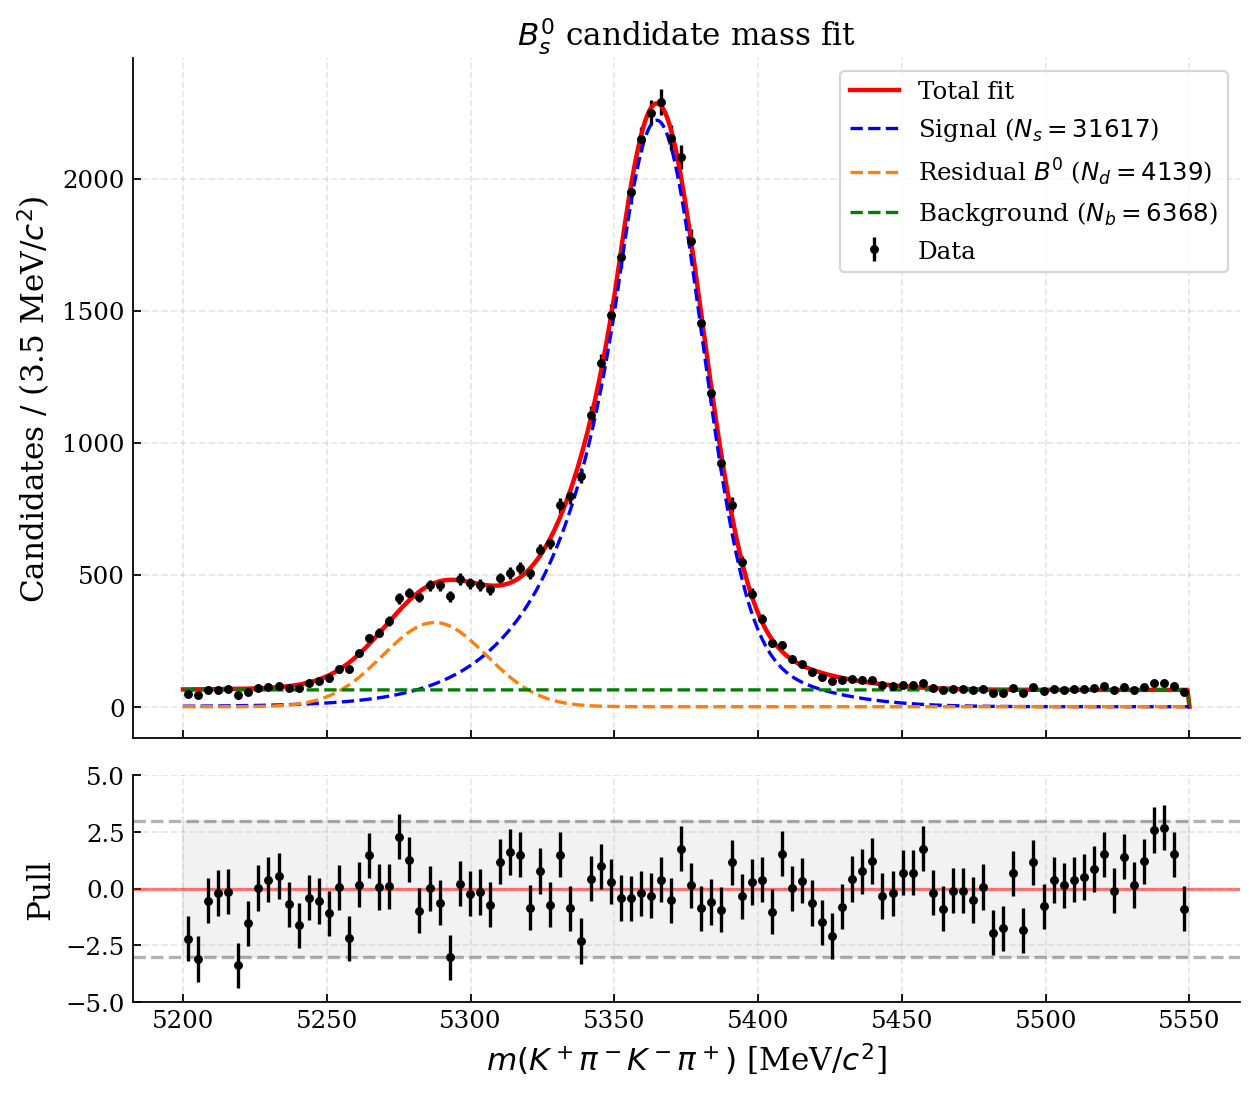

In [22]:
# Fit with pull distribution
fig = plotting.plot_fit_with_pulls(mass, fit_result)
fig.savefig("figures/mass_fit.png", dpi=160, bbox_inches="tight")


Inspect fit validity, parameters at limits and the pull distribution together. Yield and mass errors below are statistical fit uncertainties; systematic variations and model dependence are not included.


## Signal-weighted mass projections

The sPlot method assigns a statistical signal weight using the fitted component densities and yields. A signal-weighted projection is unbiased only when the projected variable and discriminating mass are sufficiently independent within each component. Decay kinematics alone does not guarantee this assumption. These projections are exploratory and do not establish resonance fractions.

The implementation follows the S1 Lecture 24 example and uses the `sweights` package; method references are listed in the README.


In [23]:
# Restrict to events in the fit range
fit_mask = (df_data_clean["Bs_M"] >= FIT_RANGE[0]) & (df_data_clean["Bs_M"] <= FIT_RANGE[1])
df_fit = df_data_clean[fit_mask].reset_index(drop=True)
mass_fit = df_fit["Bs_M"].to_numpy(float)

# Compute sWeights
sweights = analysis.compute_sweights(mass_fit, fit_result)

print(f"Sum of signal sWeights: {np.sum(sweights['signal']):.0f}  (expect ~N_sig = {p['nsig']:.0f})")
print(f"Sum of background sWeights: {np.sum(sweights['background']):.0f}  (expect ~N_bkg = {p['nbkg']:.0f})")


    PDF normalisations:
	 0 0.9999999999265522
	 1 0.9999999999999999
	 2 0.9999999999999956


    Integral of w*pdf matrix (should be close to the
                identity):
	[[ 9.99924952e-01  1.30662980e-03 -1.59796294e-03]
	 [ 3.50236805e-04  9.97561679e-01  1.64440423e-03]
	 [-2.82895077e-04  1.27061044e-03  9.99773022e-01]]
    Check of weight sums (should match yields):
	Component  | sWeightSum |   Yield    |   Diff    |
	---------------------------------------------------
	  0        | 31617.3772 | 31617.3772 |     0.00% |
	  1        |  6367.6505 |  6367.6505 |    -0.00% |
	  2        |  4138.8653 |  4138.8653 |    -0.00% |
Sum of signal sWeights: 31617  (expect ~N_sig = 31617)
Sum of background sWeights: 6368  (expect ~N_bkg = 6368)


### Opposite-sign $K\pi$ spectra

Inspect the region around the $K^*(892)$ resonance.


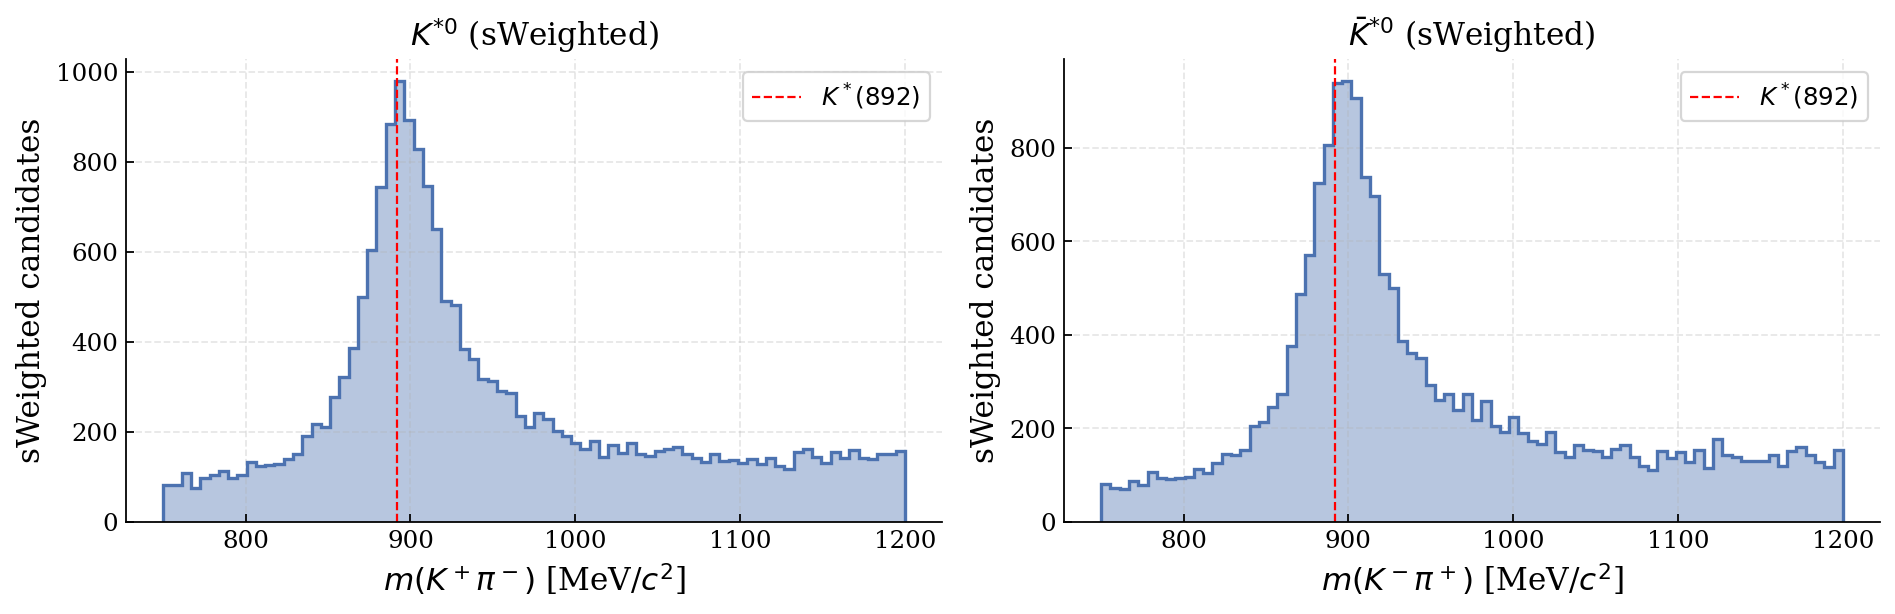

In [24]:
# Project signal into K* masses
fig = plotting.plot_sweighted_kstar(df_fit, sweights["signal"])
fig.savefig("figures/kpi_projections.png", dpi=160, bbox_inches="tight")


Enhancements near 892 MeV/$c^2$ are consistent with $K^*(892)$ contributions. Broad structures can include non-resonant signal, other partial waves and kinematic effects; sWeights do not separate those signal components.


### Other two-body combinations

Compare all six two-body masses. Structures in crossed or same-sign pairings may arise from kinematic reflections and do not by themselves imply a resonance or a failure of the weighting.


In [25]:
# Two-body invariant mass projections
_ = plotting.plot_sweighted_twobody(df_fit, sweights["signal"])


Resonance identification requires a dynamical amplitude model and acceptance treatment beyond these one-dimensional projections.


### Three-body combinations

Inspect the four three-body invariant masses for additional structure.


In [26]:
# Three-body invariant mass projections
_ = plotting.plot_sweighted_threebody(df_fit, sweights["signal"])


The broad three-body spectra provide a qualitative view of the decay kinematics. No branching fractions, amplitude fractions or CP observables are extracted.
